# Electronic Noise Simulation
Simulates the output noise power of a circuit given:
- S21 frequency response from a CSV file
- Temperature of the source (input terminal) resistor

**Model:**  
Johnson-Nyquist available noise PSD from source resistor: $P = k_B T$ (W/Hz)  
Output noise PSD after circuit: $P_{out}(f) = k_B T \cdot |S_{21}(f)|^2$ (W/Hz)  
In dBm/Hz: $P_{out}(f) = 10\log_{10}\left(\frac{k_B T}{10^{-3}}\right) + S_{21}(f)_{dB}$

## 1 · Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid

%matplotlib inline
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.grid': True,
    'grid.linestyle': '--',
    'grid.alpha': 0.5,
})

## 2 · Configuration — edit here

In [9]:
# ── File ──────────────────────────────────────────────────────────────────────
CSV_PATH = "C:\\Users\\nicoe\\OneDrive - Imperial College London\\Documents\\A Univeristy\\Year 4\\Masters Project\\Results\\S21 components\\preamp_S21.csv"        # Path to your S21 CSV file

# ── Source resistor temperature ───────────────────────────────────────────────
TEMPERATURE_K = 77.0            # Kelvin  (room temperature ≈ 290 K)

# ── Integration bandwidth (set to None to use the full CSV range) ─────────────
F_MIN = None                     # e.g. 1e6  for 1 MHz  | None = full range
F_MAX = None                     # e.g. 1e9  for 1 GHz  | None = full range

## 3 · Load S21 data

In [10]:
def load_s21_csv(filepath):
    """Load CSV and return (frequency_hz, s21_db) arrays sorted by frequency."""
    headers_used = ['Frequency (Hz)', 'S21 (dB)']
    df = pd.read_csv(filepath, comment='!', sep=',', names=headers_used, header=0)
    df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]

    freq_col = next((c for c in df.columns if "freq" in c or c in ("f", "hz")), None)
    s21_col  = next((c for c in df.columns if "s21" in c or "gain" in c or "mag" in c), None)

    if freq_col is None or s21_col is None:
        raise ValueError(
            f"Cannot identify frequency / S21 columns.\n"
            f"Found: {list(df.columns)}\n"
            f"Expected names containing 'freq' and 's21'."
        )

    print(f"Using columns → frequency: '{freq_col}', S21: '{s21_col}'")
    freq = df[freq_col].to_numpy(float)
    s21  = df[s21_col].to_numpy(float)
    idx  = np.argsort(freq)
    return freq[idx], s21[idx]


freq, s21_db = load_s21_csv(CSV_PATH)

print(f"Loaded {len(freq)} points: {freq[0]:.3g} Hz – {freq[-1]:.3g} Hz")
pd.DataFrame({"frequency_hz": freq, "s21_db": s21_db}).head()

Using columns → frequency: 'frequency_(hz)', S21: 's21_(db)'
Loaded 200 points: 8.03e+07 Hz – 1.6e+10 Hz


,frequency_hz,s21_db
0,80298500.0,-0.060668
1,160297000.0,-0.157485
2,240295500.0,-0.176579
3,320294000.0,-0.260390
4,400292500.0,-0.090193


## 4 · Compute noise PSD

In [ ]:
K_B   = 1.380649e-23   # Boltzmann constant [J/K]
REF_W = 1e3           # 1 mW reference for dBm

# Available Johnson noise PSD from source resistor [W/Hz]
source_psd_W_hz = K_B * TEMPERATURE_K
kt_floor_dbm_hz = 10 * np.log10(source_psd_W_hz / REF_W)

# Output noise PSD
s21_power        = 10 ** (s21_db / 10)                   # |S21|² (linear power ratio)
noise_psd_W_hz   = source_psd_W_hz * s21_power           # [W/Hz]
noise_psd_dbm_hz = 10 * np.log10(noise_psd_W_hz / REF_W) # [dBm/Hz]

print(f"Temperature         : {TEMPERATURE_K:.2f} K  ({TEMPERATURE_K - 273.15:.2f} °C)")
print(f"kT noise floor      : {kt_floor_dbm_hz:.2f} dBm/Hz")
print(f"Peak output noise   : {noise_psd_dbm_hz.max():.2f} dBm/Hz  @ {freq[noise_psd_dbm_hz.argmax()]:.3g} Hz")
print(f"Min  output noise   : {noise_psd_dbm_hz.min():.2f} dBm/Hz  @ {freq[noise_psd_dbm_hz.argmin()]:.3g} Hz")

Temperature         : 77.00 K  (-196.15 °C)
kT noise floor      : -179.73 dBm/Hz
Peak output noise   : -179.79 dBm/Hz  @ 8.03e+07 Hz
Min  output noise   : -189.27 dBm/Hz  @ 1.29e+10 Hz


## 5 · Integrate noise power over bandwidth

In [12]:
# Apply bandwidth limits
mask = np.ones(len(freq), dtype=bool)
if F_MIN is not None:
    mask &= freq >= F_MIN
if F_MAX is not None:
    mask &= freq <= F_MAX

f_lo = freq[mask][0]
f_hi = freq[mask][-1]

integrated_W   = trapezoid(noise_psd_W_hz[mask], freq[mask])
integrated_dbm = 10 * np.log10(integrated_W / REF_W)

print(f"Integration range   : {f_lo:.3g} Hz – {f_hi:.3g} Hz  ({mask.sum()} points)")
print(f"Integrated noise    : {integrated_dbm:.4f} dBm")

Integration range   : 8.03e+07 Hz – 1.6e+10 Hz  (200 points)
Integrated noise    : -80.4654 dBm


## 6 · Plot

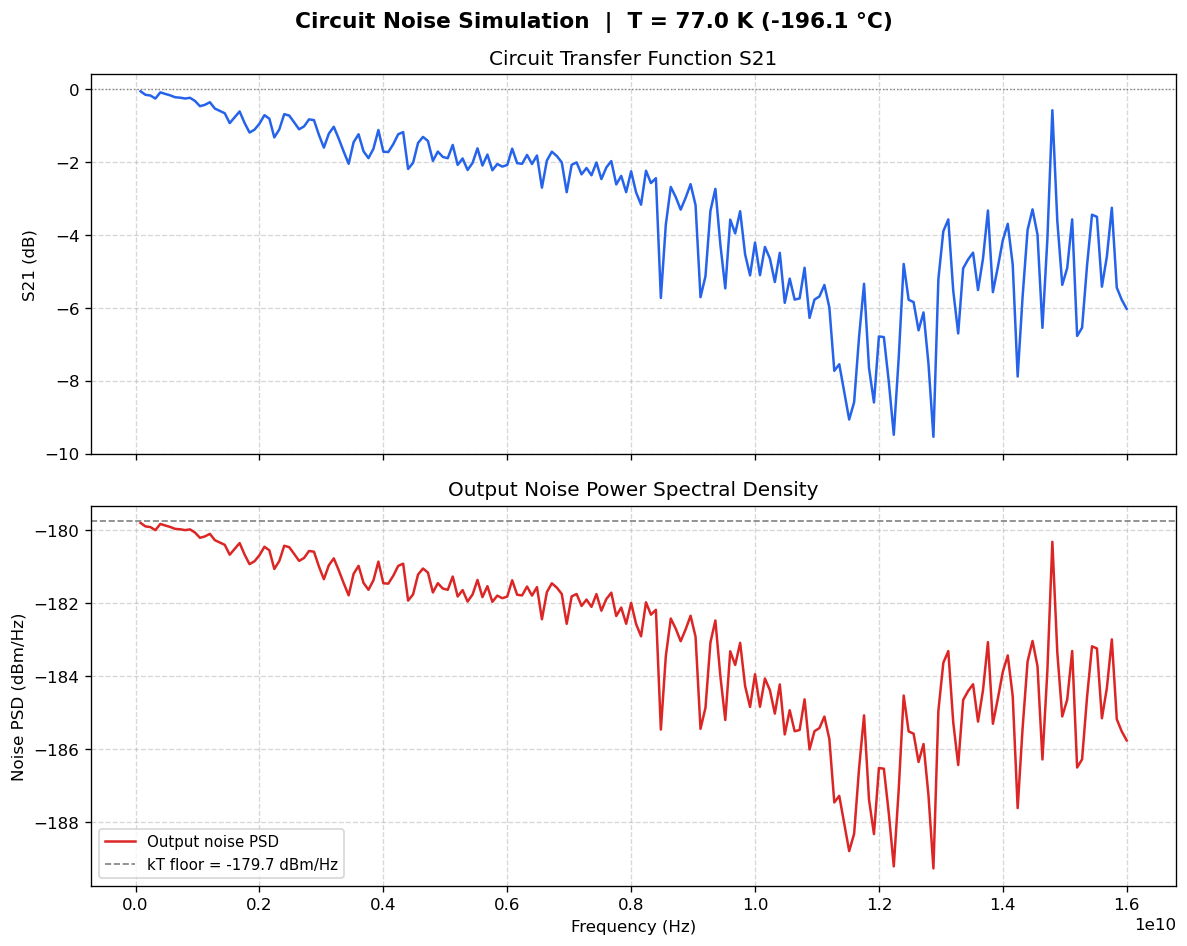

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
fig.suptitle(
    f"Circuit Noise Simulation  |  T = {TEMPERATURE_K:.1f} K ({TEMPERATURE_K - 273.15:.1f} °C)",
    fontsize=13, fontweight="bold",
)

# ── S21 ───────────────────────────────────────────────────────────────────────
axes[0].plot(freq, s21_db, color="#2563eb", linewidth=1.5)
axes[0].axhline(0, color="gray", linewidth=0.8, linestyle=":")
axes[0].set_ylabel("S21 (dB)")
axes[0].set_title("Circuit Transfer Function S21")

# ── Noise PSD ─────────────────────────────────────────────────────────────────
axes[1].plot(freq, noise_psd_dbm_hz, color="#dc2626", linewidth=1.5, label="Output noise PSD")
axes[1].axhline(kt_floor_dbm_hz, color="gray", linewidth=1.0, linestyle="--",
                label=f"kT floor = {kt_floor_dbm_hz:.1f} dBm/Hz")

# Shade integration band
# axes[1].fill_between(freq[mask], noise_psd_dbm_hz[mask], alpha=0.15,
#                      color="#dc2626",
#                      label=f"Integrated = {integrated_dbm:.2f} dBm")

axes[1].set_ylabel("Noise PSD (dBm/Hz)")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_title("Output Noise Power Spectral Density")
axes[1].legend(fontsize=9)

# for ax in axes:
    # ax.set_xscale("log")

plt.tight_layout()
# plt.savefig("noise_simulation_plot.png", dpi=150)
plt.show()

## 7 · Export results to CSV

In [ ]:
results = pd.DataFrame({
    "frequency_hz":      freq,
    "s21_db":            s21_db,
    "noise_psd_dbm_hz":  noise_psd_dbm_hz,
    "noise_psd_W_hz":    noise_psd_W_hz,
})

results.to_csv("noise_simulation_output.csv", index=False)
print("Saved → noise_simulation_output.csv")
results.head(10)